**DIAGNOSI DEL DATASET - perche' un job di anomaly detection si comporta cosi'**

In [1]:
import digitalhub as dh
import zipfile
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_NAME = "floods"
project = dh.get_project(PROJECT_NAME)
print(f"Project: {project.name}")

Project: floods


**SETUP PARAMETERS**

In [20]:
job_name = "old"

parameters = {
    "results_job": "",                        # "" = scansione senza job; con il nome di un job (anomaly_results_{results_job}) lega le immagini alla sua similarita'
    "dataset_anomalies": "Floods_Anomalies_val_crop_norm",   # artifact delle anomale da guardare (con results_job vuoto e' obbligatorio)
    "dataset_standard": "Standard",           # normali: Floods_{dataset_standard}_crop_norm
    "dataset_masks": "",                      # solo con results_job: artifact con MASK/ per l'AUROC per frazione di flood
    "flood_class": 2,
    "patch_size": 256,
    "black_thr": 0.99,                        # istante "nero" = almeno il 99% dei pixel esattamente a 0
    "max_series": 0,                          # 0 = tutte; es. 200 per una prova veloce
    "n_normal_scan": 0,                       # solo scansione: normali da campionare (0 = tante quante le anomale)
    "scan_seed": 0,
    "ref_tpr": 0.677,                         # solo scansione: TPR e FPR della vecchia regola (dalla tua matrice di confusione)
    "ref_fpr": 0.335,
    "job_name": job_name,                     # i risultati escono come diagnosi_dataset_{job_name}
}

volumes = [
    {
        "volume_type": "ephemeral",
        "name": "volume-spazio-dati",
        "mount_path": "/data",
        "spec": {"size": "500Gi"}            # scarica gli artifact delle normali e delle anomale (poi li cancella)
    }
]

**BUILD ENVIRONMENT**

In [21]:
diag_func = project.new_function(
    name=f'check_dataset_{job_name}',
    kind="python",
    python_version="PYTHON3_10",
    code_src="../src/",
    handler="data:diagnose_dataset_series",
    base_image="pytorch/pytorch:2.1.2-cuda11.8-cudnn8-runtime",     # stesso ambiente degli altri handler in src
    requirements=["pandas==2.3.3", "numpy==1.26.4", "rasterio==1.4.4", "tqdm==4.70.0", "tifffile==2024.8.30", "torch==2.1.2", "matplotlib==3.10.9", "digitalhub==0.15.11", "digitalhub-runtime-python==0.15.2", "zarr==2.18.0", "numcodecs==0.13.1", "xarray==2025.6.1", "scikit-learn==1.5.2"]
)

build = diag_func.run("build", wait=True)
print(f"BUILD: {build.status.state}")

2026-10-08 15:00:52,602 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run c4936110260947b2a28873cafe1c42e2 to finish...
2026-10-08 15:00:57,609 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run c4936110260947b2a28873cafe1c42e2 to finish...
2026-10-08 15:01:02,720 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run c4936110260947b2a28873cafe1c42e2 to finish...
2026-10-08 15:01:07,729 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run c4936110260947b2a28873cafe1c42e2 to finish...
2026-10-08 15:01:12,739 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run c4936110260947b2a28873cafe1c42e2 to finish...
2026-10-08 15:01:17,747 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run c4936110260947b2a28873cafe1c42e2 to finish...
2026-10-08 15:01:22,756 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run c4936110260947b2a28873cafe1c42e2 to finish...
2026-10-08 15

BUILD: COMPLETED


**DIAGNOSI** (solo lettura dei dati, nessuna GPU: usa il profilo CPU)

In [22]:
run_diag = diag_func.run(
    action="job",
    parameters=parameters,
    volumes=volumes,
    profile="cpu-shared",
    local_execution=False,
    wait=True
)

print(f"Run diagnosi avviato: {run_diag.id}")

2026-10-08 15:01:53,089 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run f313f4550d7e4f89a0db372d36e969e7 to finish...
2026-10-08 15:01:58,096 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run f313f4550d7e4f89a0db372d36e969e7 to finish...
2026-10-08 15:02:03,105 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run f313f4550d7e4f89a0db372d36e969e7 to finish...
2026-10-08 15:02:08,114 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run f313f4550d7e4f89a0db372d36e969e7 to finish...
2026-10-08 15:02:13,123 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run f313f4550d7e4f89a0db372d36e969e7 to finish...
2026-10-08 15:02:18,131 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run f313f4550d7e4f89a0db372d36e969e7 to finish...
2026-10-08 15:02:23,140 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run f313f4550d7e4f89a0db372d36e969e7 to finish...
2026-10-08 15

Run diagnosi avviato: f313f4550d7e4f89a0db372d36e969e7


**RESULTS**

In [23]:
RESULTS_DIR = "/tmp/diagnosi_dataset"

zip_path = project.get_artifact(f"diagnosi_dataset_{job_name}").download("/tmp/diagnosi_dataset.zip", overwrite=True)
with zipfile.ZipFile(zip_path) as z:
    z.extractall(RESULTS_DIR)

print(open(f"{RESULTS_DIR}/report.txt").read())

=== Scansione senza job: 2171 normali (campione di Floods_Standard_crop_norm), 2171 anomale (da Floods_Anomalies_val_crop_norm) ===

=== Istanti neri: un istante e' 'nero' se almeno il 99% dei suoi pixel vale esattamente 0 ===
 gruppo    n serie con >=1 istante OTTICO nero serie con >=1 istante SAR nero ottico: zeri nell'istante peggiore (mediana) ottico: zeri nell'istante peggiore (p90) SAR: zeri nell'istante peggiore (mediana)
normali 2171                              0.0%                           0.0%                                         4.5%                                     7.3%                                      3.3%
anomale 2171                              0.0%                           0.0%                                         5.1%                                     7.8%                                      3.7%
Dimensioni array ottico (H x W) normali: 256x256: 2171
Dimensioni array ottico (H x W) anomale: 256x256: 2171

=== Quota di zeri nell'istante ottico peggio

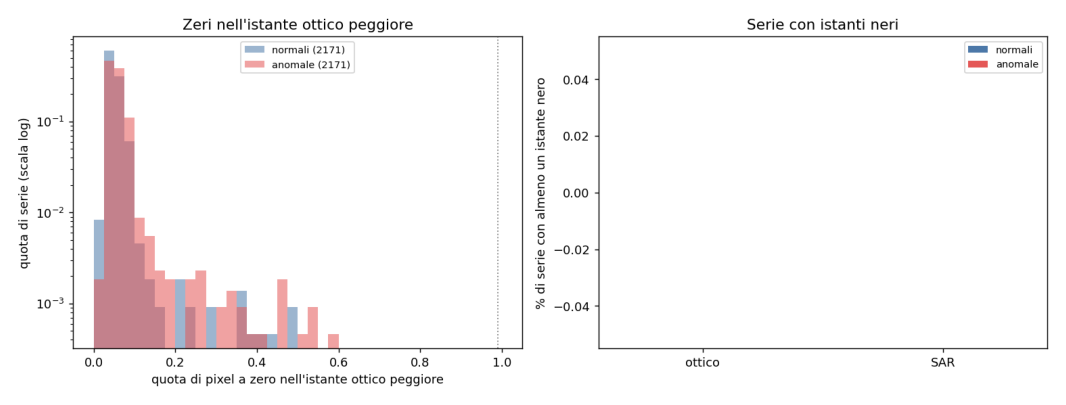

In [24]:
img = plt.imread(f"{RESULTS_DIR}/diagnosi_dataset.png")
plt.figure(figsize=(18, 5))
plt.imshow(img)
plt.axis("off")
plt.show()

In [25]:
pd.set_option("display.width", 250, "display.max_columns", 40, "display.max_colwidth", 40)
stats = pd.read_csv(f"{RESULTS_DIR}/stats_series.csv")
cols = [c for c in ["ID", "label", "sim", "opt_n_black", "opt_zero_max", "sar_n_black", "opt_H", "opt_W"] if c in stats.columns]
stats.sort_values("opt_zero_max", ascending=False).head(20)[cols]

,ID,label,opt_n_black,opt_zero_max,sar_n_black,opt_H,opt_W
2652,EMSR419_5_40RHP_x257095_y2798805,1,0,0.581538,0,256,256
2668,EMSR419_5_40RHP_x272455_y2796245,1,0,0.537520,0,256,256
2663,EMSR419_5_40RHP_x267335_y2796245,1,0,0.535027,0,256,256
2646,EMSR419_5_40RHP_x254535_y2798805,1,0,0.512527,0,256,256
127,EMSR548_1_33SWB_x507805_y4132425,0,0,0.478987,0,256,256
1782,EMSR427_2_33VUD_x349955_y6347925,0,0,0.478365,0,256,256
2671,EMSR419_5_40RHP_x275015_y2796245,1,0,0.457036,0,256,256
2650,EMSR419_5_40RHP_x254535_y2809045,1,0,0.455316,0,256,256
2666,EMSR419_5_40RHP_x269895_y2796245,1,0,0.454562,0,256,256
2655,EMSR419_5_40RHP_x259655_y2798805,1,0,0.450423,0,256,256
